# Lab 11 — Airline tweets: text visualization and customer priorities
**24I-2513 | BDS-5B**

**Data Analysis and Visualization | Parts A–F**  
Source: supplied `dataset/Tweets.csv`, a historical 2015 sample. All figures are calculated below. Human sentiment and complaint reasons are annotations, not verified service outcomes. No airline is assumed to be the client; recommendations compare all six.

This notebook is also exported as a self-contained HTML report. Run all cells from this folder; install `requirements.txt` first. The first run downloads NLTK resources. The original data is retained and a cleaned, scored dataset is generated.

In [1]:
from pathlib import Path
import re, html, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from wordcloud import WordCloud
from IPython.display import display, Markdown
for resource in ['stopwords', 'wordnet', 'omw-1.4', 'vader_lexicon']:
    nltk.download(resource, quiet=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
sns.set_palette(['#b64949','#8193a3','#25856b'])
pd.set_option('display.max_colwidth', 180)
raw=pd.read_csv('dataset/Tweets.csv', dtype={'tweet_id': str})
print('Original rows:', len(raw), '| duplicate IDs:', raw.tweet_id.duplicated().sum(), '| missing text:', raw.text.isna().sum())
df=raw.drop_duplicates('tweet_id').dropna(subset=['text','airline_sentiment']).copy()
print('Analysis rows:', len(df), '| repeated text (retained if distinct IDs):', df.text.duplicated().sum())
print('Missing values per column:'); display(raw.isna().sum().to_frame('missing'))
df['date']=pd.to_datetime(df.tweet_created, utc=True).dt.floor('D')
print('UTC coverage:', pd.to_datetime(df.tweet_created, utc=True).min(), 'to', pd.to_datetime(df.tweet_created, utc=True).max())
labels=['negative','neutral','positive']
display(df.airline_sentiment.value_counts().to_frame('tweets'))

Original rows: 14640 | duplicate IDs: 155 | missing text: 0
Analysis rows: 14485 | repeated text (retained if distinct IDs): 58
Missing values per column:


,missing
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5462
negativereason_confidence,4118
airline,0
airline_sentiment_gold,14600
name,0
negativereason_gold,14608
retweet_count,0


UTC coverage: 2015-02-17 07:36:05+00:00 to 2015-02-24 19:53:37+00:00


,tweets
airline_sentiment,
negative,9082
neutral,3069
positive,2334


## Part A — Cleaning with an audit trail
Whitespace splitting preserves punctuation stuck to words, links and handles; a generic word regex fragments links and contractions. A tweet-aware tokenizer recognizes these units. Remove handles and URLs from **topic counts**, unwrap hashtags, decode HTML, lowercase and reduce excessive repeats to three characters. Keep emojis in the tokenization audit, but exclude nonalphabetic tokens from the word vocabulary. This loses affect, so **VADER always receives original text**, preserving punctuation, capitalization, emoticons and negation. Unicode emoji coverage in VADER is limited.

We preserve negators (`no`, `not`, `nor`, `never`, `n't` forms). Content-word n-grams after stop-word removal can invent adjacency, so phrase charts use contiguous tokens before stop-word removal. Lemmatization uses a conservative noun default: it reduces plurals without aggressive stemming, but misses verb normalization. No claim of full linguistic normalization is made.

In [2]:
tok=TweetTokenizer(preserve_case=False, reduce_len=True)
examples=['@United soooo unhappy! #Delayed https://t.co/abc 😡', "@JetBlue I am not happy &amp; I can't fly :("]
display(pd.DataFrame({'text':examples,'whitespace':[s.split() for s in examples], 'word_regex':[re.findall(r"\w+",s) for s in examples], 'tweet_tokens':[tok.tokenize(html.unescape(s)) for s in examples]}))
stop=set(stopwords.words('english'))
negators={'no','not','nor','never',"n't"}
stop_final={w for w in stop if w not in negators and not w.endswith("n't")}
airline_words={'united','usairways','americanair','southwestair','jetblue','virginamerica','southwest','american','airways','virgin','america','airline','airlines','rt','amp'}
lemma=WordNetLemmatizer(); stem=PorterStemmer()
def normalized(s):
    s=html.unescape(s)
    s=re.sub(r'https?://\S+|www\.\S+',' ',s)
    s=re.sub(r'@\w+',' ',s)
    return tok.tokenize(s.replace('#',''))
def lexical(ts):
    return [t for t in ts if re.fullmatch(r"[a-z]+(?:'[a-z]+)?",t)]
s0=df.text.map(str.split)
s1=df.text.map(normalized)
s2=s1.map(lexical)
s3=s2.map(lambda ts:[t for t in ts if t not in stop_final])
s4=s3.map(lambda ts:[t for t in ts if t not in airline_words])
s5=s4.map(lambda ts:[lemma.lemmatize(t) for t in ts])
audit=[]
for name,series in [('Raw whitespace',s0),('Decode, remove handles/URLs, tokenize',s1),('Alphabetic vocabulary',s2),('Stop words except negation',s3),('Airline terms and filler',s4),('Noun lemmatization',s5)]:
    audit.append({'stage':name,'vocabulary':len(set(t for ts in series for t in ts)),'mean_tokens':series.map(len).mean(),'empty_tweets':series.map(len).eq(0).sum()})
audit=pd.DataFrame(audit)
audit['vocabulary_change']=audit.vocabulary.diff()
audit['mean_token_change']=audit.mean_tokens.diff()
display(audit.round(2))
vocab=sorted(set(t for ts in s4 for t in ts))
print('Vocabulary sizes: original',len(vocab),'stemmed',len({stem.stem(t) for t in vocab}),'lemmatized',len({lemma.lemmatize(t) for t in vocab}))
words=['delayed','delays','cancelled','cancellation','services','better','flying','luggage','customers','united']
display(pd.DataFrame({'word':words,'stem':[stem.stem(w) for w in words],'lemma':[lemma.lemmatize(w) for w in words]}))
df['tokens']=s5; df['clean_text']=s5.map(' '.join)
vader=SentimentIntensityAnalyzer()
def predict(score): return 'positive' if score>=.05 else 'negative' if score<=-.05 else 'neutral'
df['vader_compound']=df.text.map(lambda s:vader.polarity_scores(s)['compound'])
df['vader_label']=df.vader_compound.map(predict)
# Controlled ablation: remove only negators, rather than confounding all cleaning steps.
def remove_negation(s):
    s=re.sub(r"(?i)n['’]t\b",'',s)
    return re.sub(r'(?i)\b(no|not|nor|never)\b','',s)
without=df.text.map(remove_negation).map(lambda s:predict(vader.polarity_scores(s)['compound']))
print('Original-text accuracy:',accuracy_score(df.airline_sentiment,df.vader_label))
print('Negation-removed accuracy:',accuracy_score(df.airline_sentiment,without))
print('Predictions changed:',(without!=df.vader_label).sum())
neg_examples=['The service is not good.','I am not happy.','No help from the airline.','The flight was not bad.']
display(pd.DataFrame([{'original':s,'without_negation':remove_negation(s),'original_score':vader.polarity_scores(s)['compound'],'ablated_score':vader.polarity_scores(remove_negation(s))['compound']} for s in neg_examples]))

,text,whitespace,word_regex,tweet_tokens
0,@United soooo unhappy! #Delayed https://t.co/abc 😡,"[@United, soooo, unhappy!, #Delayed, https://t.co/abc, 😡]","[United, soooo, unhappy, Delayed, https, t, co, abc]","[@united, sooo, unhappy, !, #delayed, https://t.co/abc, 😡]"
1,@JetBlue I am not happy &amp; I can't fly :(,"[@JetBlue, I, am, not, happy, &amp;, I, can't, fly, :(]","[JetBlue, I, am, not, happy, amp, I, can, t, fly]","[@jetblue, i, am, not, happy, &, i, can't, fly, :(]"


,stage,vocabulary,mean_tokens,empty_tweets,vocabulary_change,mean_token_change
0,Raw whitespace,30105,17.66,0,NaN,NaN
1,"Decode, remove handles/URLs, tokenize",14270,18.87,0,-15835.0,1.21
2,Alphabetic vocabulary,11135,15.81,3,-3135.0,-3.06
3,Stop words except negation,10973,8.80,24,-162.0,-7.01
4,Airline terms and filler,10959,8.70,26,-14.0,-0.10
5,Noun lemmatization,10077,8.70,26,-882.0,0.00


Vocabulary sizes: original 10959 stemmed 8338 lemmatized 10077


,word,stem,lemma
0,delayed,delay,delayed
1,delays,delay,delay
2,cancelled,cancel,cancelled
3,cancellation,cancel,cancellation
4,services,servic,service
5,better,better,better
6,flying,fli,flying
7,luggage,luggag,luggage
8,customers,custom,customer
9,united,unit,united


Original-text accuracy: 0.5426993441491198
Negation-removed accuracy: 0.4994822229892993
Predictions changed: 1138


,original,without_negation,original_score,ablated_score
0,The service is not good.,The service is good.,-0.3412,0.4404
1,I am not happy.,I am happy.,-0.4585,0.5719
2,No help from the airline.,help from the airline.,0.1280,0.4019
3,The flight was not bad.,The flight was bad.,0.4310,-0.5423


**Cleaning decision.** Stems such as `servic` and `cancel` can be useful for retrieval but make director-facing labels harder to read. Choose noun lemmatization and report its limited scope. Empty content rows remain in sentiment and airline denominators; they are not silently dropped. Removing all alphabetic noise is too aggressive for sentiment, and reducing stretched words can erase intensity. Those steps are restricted to topic visualization. A small change in total accuracy after deleting negation does not justify deleting it: the controlled examples show meaning reversal, and aggregate errors can cancel out.

## Part B — Words, distinctive language and operational phrases
Counts measure repeated occurrences, not passengers. TF-IDF is fitted at the individual tweet level (`min_df=5`); class means reveal relative distinctive language without giving the larger negative class more weight. Positive-minus-negative differences can still reflect topic and sampling differences rather than causal sentiment.

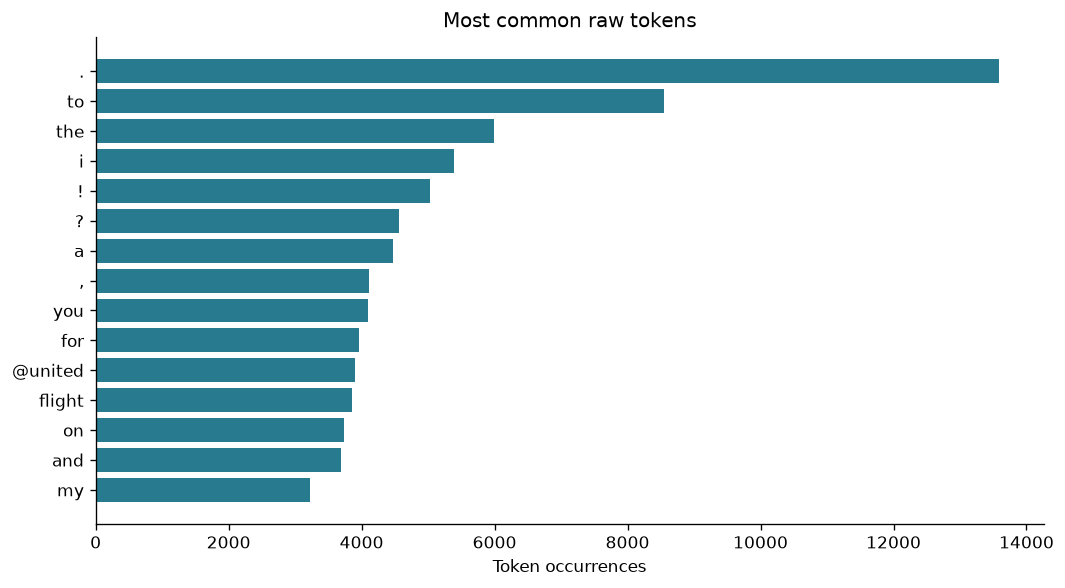

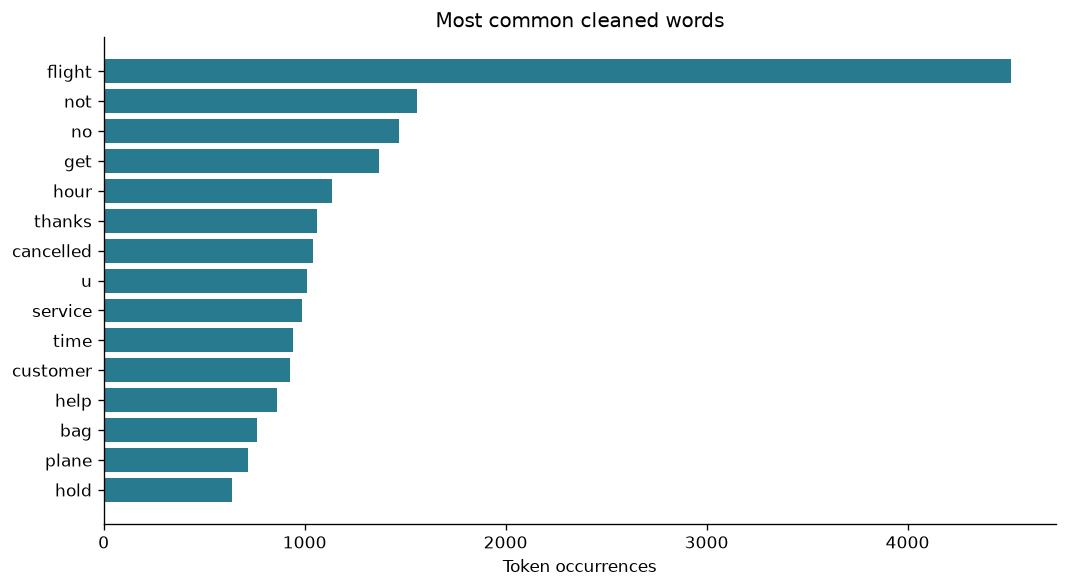

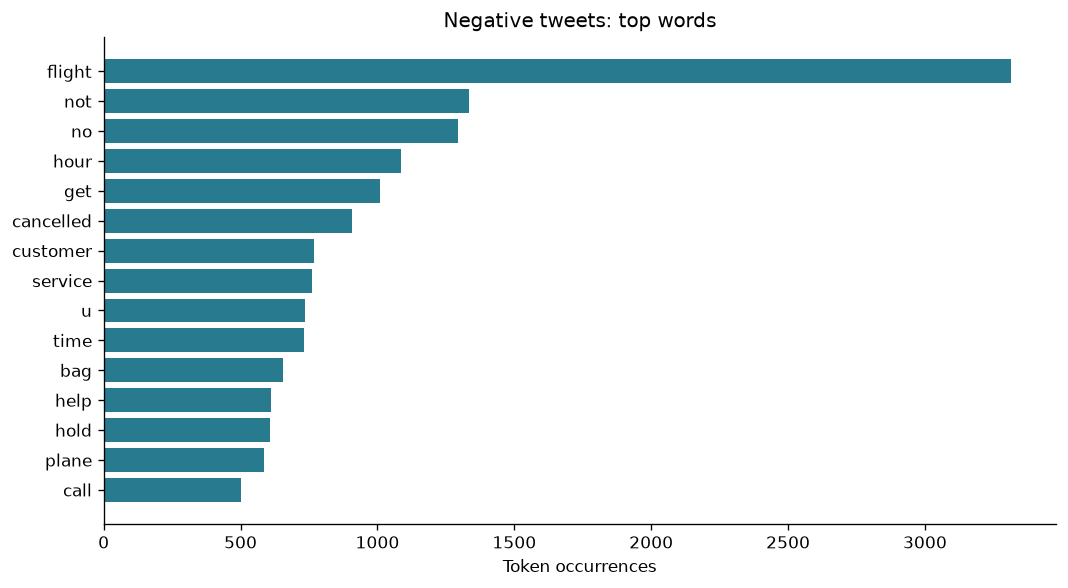

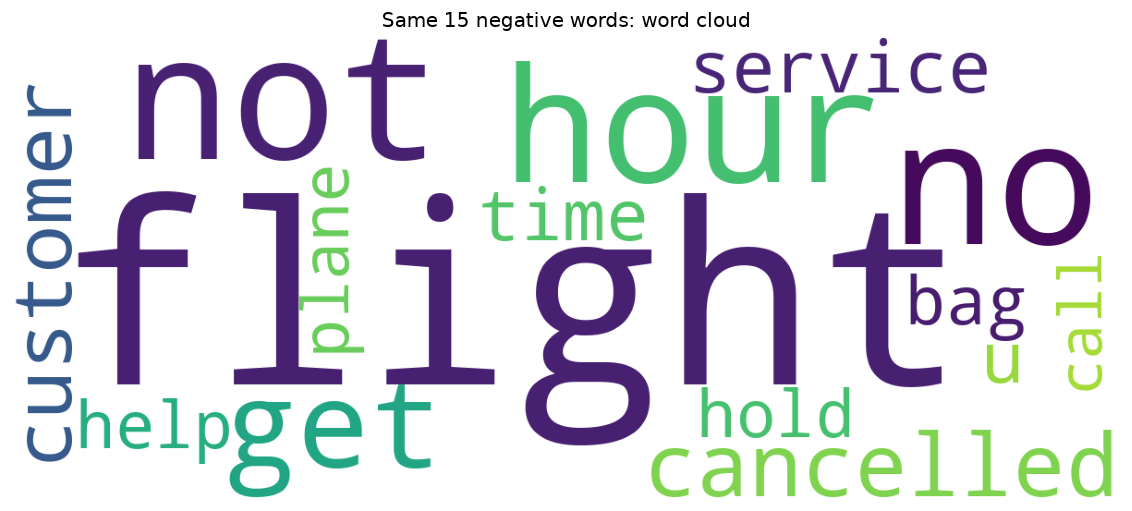

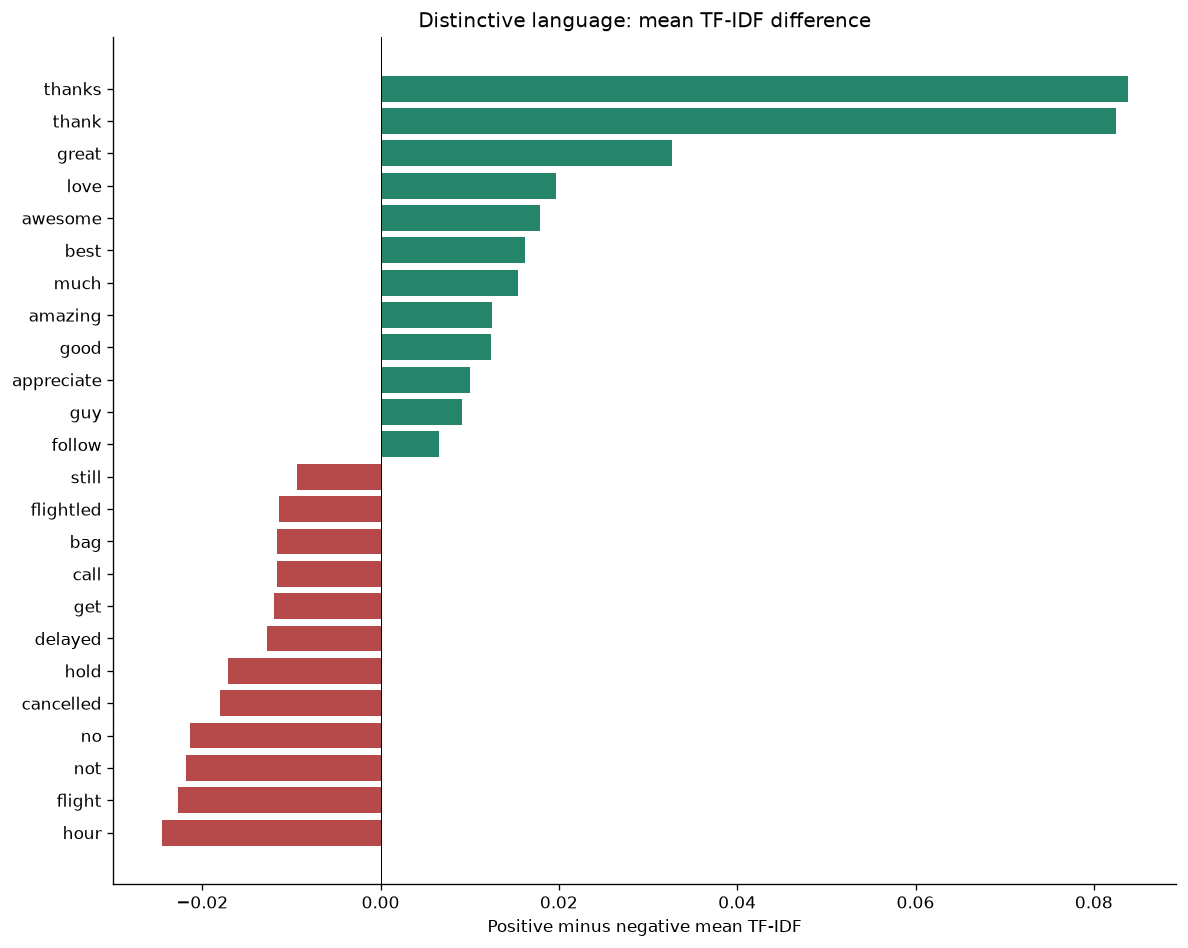

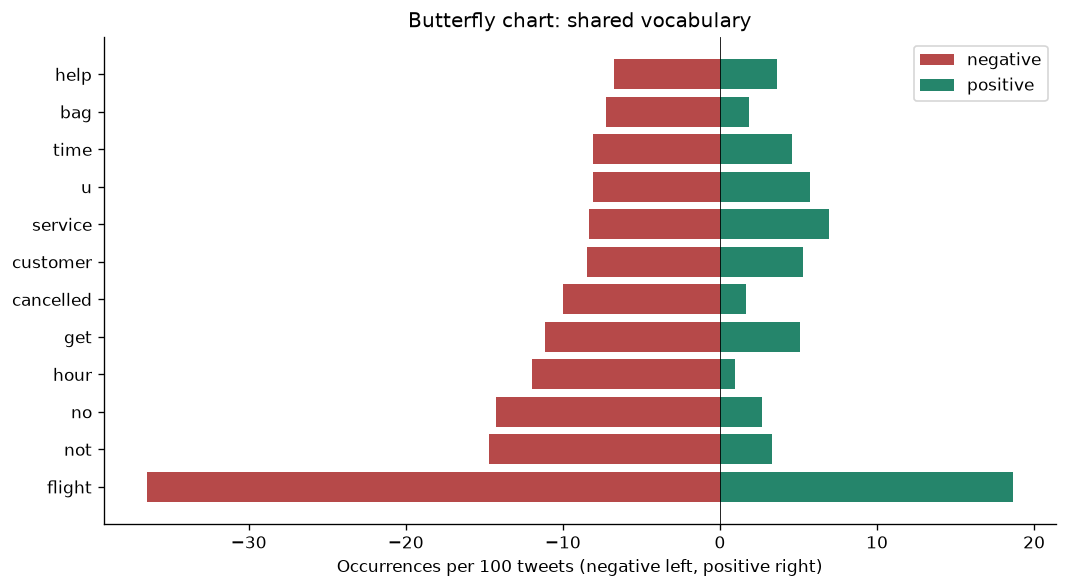

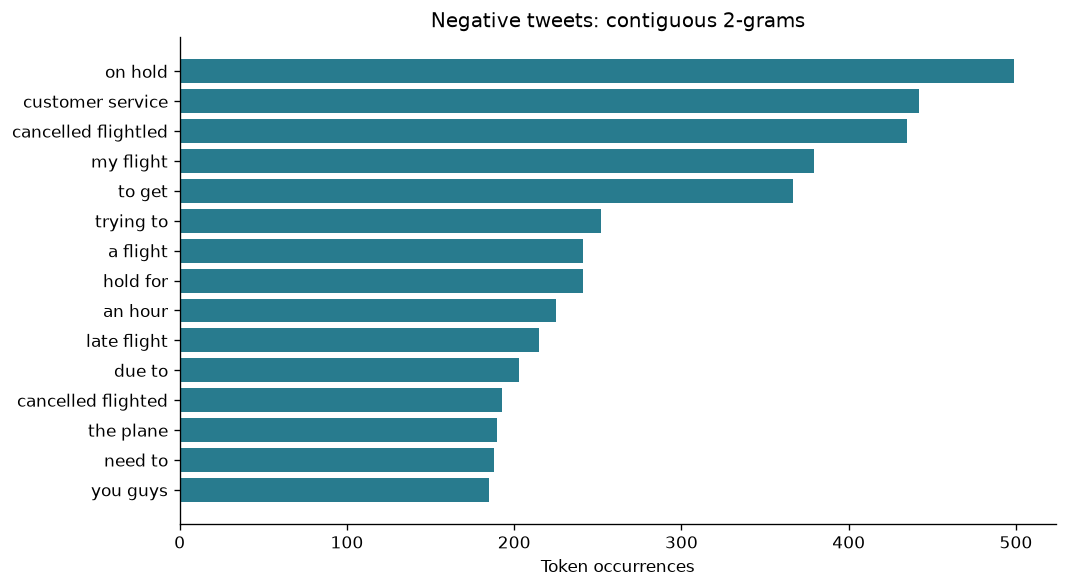

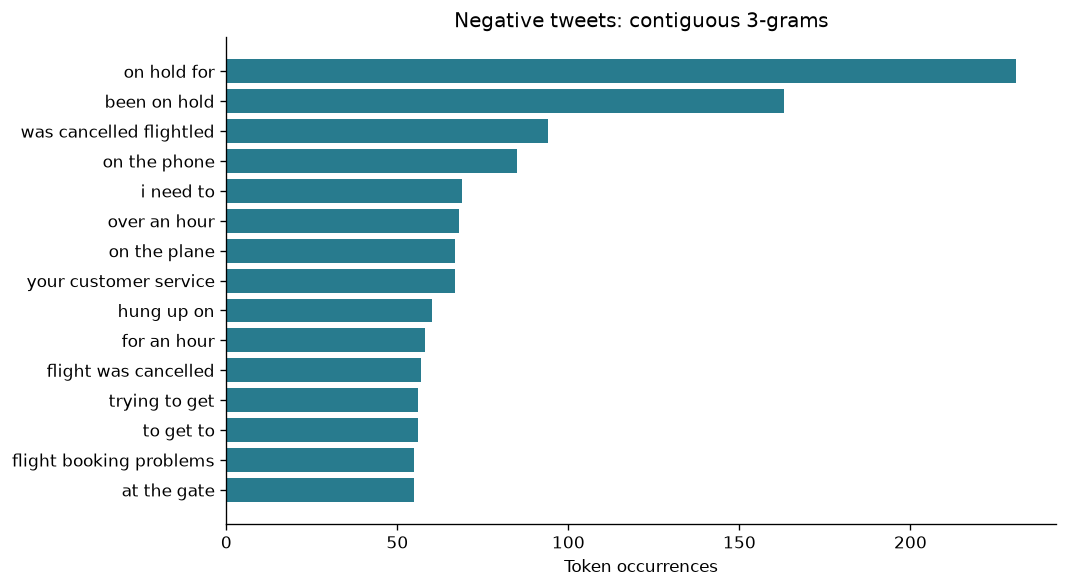

,phrase,negative_occurrences
0,customer service,442
1,cancelled flight,122
2,flight cancelled,74
3,on hold,499
4,not happy,21


In [3]:
def counts(series): return Counter(t for ts in series for t in ts)
def bar(counter,title,n=15):
    items=counter.most_common(n)
    fig,ax=plt.subplots(figsize=(9,5))
    ax.barh([x[0] for x in items][::-1],[x[1] for x in items][::-1],color='#287b8e')
    ax.set(title=title,xlabel='Token occurrences'); plt.tight_layout(); plt.show()
bar(counts(df.text.map(lambda s:tok.tokenize(s))), 'Most common raw tokens')
bar(counts(df.tokens),'Most common cleaned words')
negative=counts(df.loc[df.airline_sentiment.eq('negative'),'tokens'])
bar(negative,'Negative tweets: top words')
cloud=WordCloud(width=1200,height=500,background_color='white',random_state=42,collocations=False).generate_from_frequencies(dict(negative.most_common(15)))
plt.figure(figsize=(12,5));plt.imshow(cloud);plt.axis('off');plt.title('Same 15 negative words: word cloud');plt.show()
vec=TfidfVectorizer(tokenizer=str.split,token_pattern=None,lowercase=False,min_df=5)
X=vec.fit_transform(df.clean_text); terms=np.array(vec.get_feature_names_out())
means={label:np.asarray(X[df.airline_sentiment.eq(label).to_numpy()].mean(axis=0)).ravel() for label in labels}
delta=means['positive']-means['negative']; ix=np.r_[np.argsort(delta)[:12],np.argsort(delta)[-12:]]
fig,ax=plt.subplots(figsize=(10,8));ax.barh(terms[ix],delta[ix],color=['#b64949' if x<0 else '#25856b' for x in delta[ix]])
ax.axvline(0,color='black',lw=.6);ax.set(title='Distinctive language: mean TF-IDF difference',xlabel='Positive minus negative mean TF-IDF');plt.tight_layout();plt.show()
# Back-to-back rates on common words, allowing unequal class sizes.
words=[w for w,_ in negative.most_common(12)]
fig,ax=plt.subplots(figsize=(9,5)); y=np.arange(len(words))
for label,sign,color in [('negative',-1,'#b64949'),('positive',1,'#25856b')]:
    subset=df.loc[df.airline_sentiment.eq(label),'tokens']; ct=counts(subset)
    ax.barh(y,[sign*100*ct[w]/len(subset) for w in words],label=label,color=color)
ax.set_yticks(y,words);ax.axvline(0,color='black',lw=.5);ax.set_xlabel('Occurrences per 100 tweets (negative left, positive right)');ax.set_title('Butterfly chart: shared vocabulary');ax.legend();plt.tight_layout();plt.show()
# Retain original adjacency and punctuation boundaries: do not bridge removed tokens.
def phrases(s,n):
    ts=tok.tokenize(html.unescape(s))
    result=[]
    for i in range(len(ts)-n+1):
        window=ts[i:i+n]
        if all(re.fullmatch("[a-z]+(?:'[a-z]+)?",t) for t in window) and not any(t in airline_words for t in window) and any(t not in stop for t in window):
            result.append(' '.join(window))
    return result
for n in [2,3]:
    pc=counts(df.loc[df.airline_sentiment.eq('negative'),'text'].map(lambda s:phrases(s,n)))
    bar(pc,f'Negative tweets: contiguous {n}-grams')
phrase_counts=counts(df.loc[df.airline_sentiment.eq('negative'),'text'].map(lambda s:phrases(s,2)))
display(pd.DataFrame([(w,phrase_counts[w]) for w in ['customer service','cancelled flight','flight cancelled','on hold','not happy']],columns=['phrase','negative_occurrences']))

**Interpretation.** Airline handles dominate raw text because these tweets were directed at or mention airlines; this is consistent with collection by airline queries, not a random passenger survey. “Customer service” and “on hold” identify contact-channel problems; “cancelled flight” / “flight cancelled” identify disrupted travel. “Not happy” reverses the positive meaning of “happy.” The counts above establish which phrases occur in this file.

Show the Director the **bar chart**: a common baseline supports precise comparisons. The cloud uses font size with layout and word-length effects, so perceived visual area is not a reliable frequency scale. It is useful only as a quick introduction. Raw frequency misses separative language because frequent words like “flight” occur in both classes, and negative tweets are much more numerous. The normalized butterfly and TF-IDF differences address different parts of that problem.

## Part C — Can VADER replace readers?
VADER scores the original tweet, with conventional compound thresholds of -0.05 and +0.05. Accuracy is agreement with the supplied labels, not objective truth. Report precision, recall, F1, a majority baseline and a confusion matrix because class imbalance hides failures.

,precision,recall,f1-score,support
negative,0.898,0.497,0.640,9082.000
neutral,0.385,0.428,0.405,3069.000
positive,0.336,0.871,0.485,2334.000
accuracy,0.543,0.543,0.543,0.543
macro avg,0.540,0.599,0.510,14485.000
weighted avg,0.699,0.543,0.565,14485.000


Accuracy 54.3%; majority baseline 62.7%; macro-F1 0.510


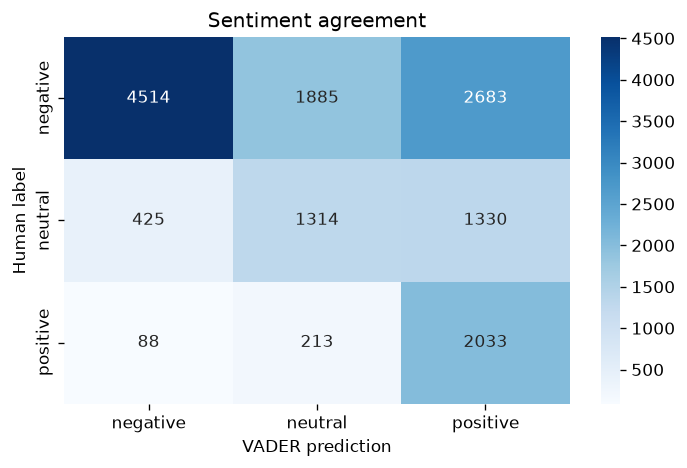

Hardest class by F1: neutral
Confidence >= 0.8: n=10340, accuracy=0.586, macro F1=0.528
Confidence >= 0.9: n=10339, accuracy=0.586, macro F1=0.528
Confidence >= 1.0: n=10326, accuracy=0.586, macro F1=0.528


,disagreements
cause_proxy,
Other / requires manual review,3463
Negation cue,1699
Mixed-feeling cue,687
Operational vocabulary cue,643
Sarcasm or polite complaint cue,132


,text,airline_sentiment,vader_label,vader_compound,cause_proxy
5947,@SouthwestAir Report was filed but would like to support some active searching. Feels pretty passive now. Info on computer is precious.,negative,positive,0.9716,Mixed-feeling cue
2437,@united What a really GREAT &amp; FLATTERING story about you! You should be very proud :) http://t.co/oKtUkjY92O (via @ParachuteGuy),negative,positive,0.9467,Other / requires manual review
7244,@JetBlue not an issue but I think training &amp; information would help. Great ppl but service needs to switch from individual to group better,negative,positive,0.9331,Mixed-feeling cue
2421,@united Just let the employees know that good service and a kind attitude towards customers is vital in this kind of business. Thanks,negative,positive,0.9300,Other / requires manual review
752,@united The bright side would be keeping the promise that was made to me. Hope you're having a good night. Thanks.,negative,positive,0.9169,Other / requires manual review
1740,@United Personal Device Entertainment system is great but with app crashing every 10/15 mins I'm glad it's free for now.,negative,positive,0.9169,Mixed-feeling cue
1072,@united Thanks! I'll fill up the form as soon as I land. I don't like being duped so I hope you will appreciate my feedback &amp; will be better,negative,positive,0.9145,Negation cue
8913,@JetBlue figured but delay is listed at almost 2 hrs. Thanks for being great! Cheers,negative,positive,0.9113,Sarcasm or polite complaint cue
591,"@united I just sent an email to Customer Care, telling them I may have to break up with you 😢. I sincerely hope they can help me!!",negative,positive,0.9097,Other / requires manual review
9637,@USAirways I love how just to give feedback to this link I have to fill out all my personal info on a form. You guys are the best :),negative,positive,0.9081,Other / requires manual review


,constructed_tweet,neg,neu,pos,compound,predicted
0,"Great, another cancelled flight. Just what I needed.",0.18,0.45,0.369,0.4767,positive
1,My flight is canceled and I am stranded overnight.,0.00,1.00,0.000,0.0000,neutral
2,"The agent said ""happy to help"" and then hung up on me.",0.00,0.61,0.390,0.7506,positive


Operational lexicon entries: {'delayed': -0.9, 'cancelled': -1.0, 'canceled': 'NOT IN LEXICON', 'stranded': 'NOT IN LEXICON'}


In [4]:
report=classification_report(df.airline_sentiment,df.vader_label,labels=labels,output_dict=True,zero_division=0)
display(pd.DataFrame(report).T.round(3))
accuracy=accuracy_score(df.airline_sentiment,df.vader_label)
baseline=df.airline_sentiment.value_counts(normalize=True).max()
print(f'Accuracy {accuracy:.1%}; majority baseline {baseline:.1%}; macro-F1 {f1_score(df.airline_sentiment,df.vader_label,average="macro"):.3f}')
cm=confusion_matrix(df.airline_sentiment,df.vader_label,labels=labels)
fig,ax=plt.subplots(figsize=(6,4));sns.heatmap(cm,annot=True,fmt='d',xticklabels=labels,yticklabels=labels,cmap='Blues',ax=ax);ax.set(xlabel='VADER prediction',ylabel='Human label',title='Sentiment agreement');plt.tight_layout();plt.show()
hardest=min(labels,key=lambda x:report[x]['f1-score']);print('Hardest class by F1:',hardest)
for threshold in [.8,.9,1.0]:
    sub=df[df.airline_sentiment_confidence>=threshold]
    print(f'Confidence >= {threshold}: n={len(sub)}, accuracy={accuracy_score(sub.airline_sentiment,sub.vader_label):.3f}, macro F1={f1_score(sub.airline_sentiment,sub.vader_label,labels=labels,average="macro",zero_division=0):.3f}')
# Rank severe disagreements by distance from the numerical human class target.
errors=df[df.airline_sentiment!=df.vader_label].copy()
errors['distance']=(errors.vader_compound-errors.airline_sentiment.map({'negative':-1,'neutral':0,'positive':1})).abs()
def cause(s):
    s=s.lower()
    if re.search(r'\b(thanks|thank|great|awesome|love)\b',s) and re.search(r'\b(delay|delayed|cancelled|canceled|lost|hours|worst|nothing|hold)\b',s): return 'Sarcasm or polite complaint cue'
    if re.search(r'\b(but|although|however|though)\b',s): return 'Mixed-feeling cue'
    if re.search(r"\b(no|not|never|nor)\b|n't",s): return 'Negation cue'
    if re.search(r'\b(delay|delayed|cancelled|canceled|hold|baggage|luggage|missed|stranded)\b',s): return 'Operational vocabulary cue'
    return 'Other / requires manual review'
errors['cause_proxy']=errors.text.map(cause)
display(errors.cause_proxy.value_counts().to_frame('disagreements'))
display(errors.sort_values('distance',ascending=False)[['text','airline_sentiment','vader_label','vader_compound','cause_proxy']].head(20))
errors.to_csv('dataset/sentiment_disagreements.csv',index=False)
custom=['Great, another cancelled flight. Just what I needed.', 'My flight is canceled and I am stranded overnight.', 'The agent said "happy to help" and then hung up on me.']
display(pd.DataFrame([{'constructed_tweet':s,**vader.polarity_scores(s),'predicted':predict(vader.polarity_scores(s)['compound'])} for s in custom]))
print('Operational lexicon entries:',{w:vader.lexicon.get(w,'NOT IN LEXICON') for w in ['delayed','cancelled','canceled','stranded']})

**Error diagnosis and fixes.** The cause table is a transparent, ordered heuristic screen, not a validated causal annotation. Sarcasm/politeness is checked first, then mixed feelings, negation and domain vocabulary; causes overlap. “Other” must not be re-labelled as a known cause. The most severe examples above permit inspection, but a representative human-coded sample is required to establish the largest true cause. The largest identifiable **proxy** is reported in the findings below.

Operational terms need domain adaptation; sarcastic praise needs context; mixed tweets need aspect-level labels; negation scope needs targeted tests. Add airline-specific training examples, evaluate on a held-out, human-adjudicated set and retain human escalation. Do not tune on this dataset and claim an unbiased improvement.

In the three constructed failures: sarcastic “Great” produces a positive score of 0.4767 despite cancellation; “canceled” and “stranded” are absent from this lexicon and produce neutral 0.0 despite disruption; the quoted “happy to help” produces positive 0.7506 despite the agent hanging up. Literal word scores do not recover speaker intent or service outcome. Not all domain words are missing: “delayed” and “cancelled” do have negative weights, so spelling and context matter.

Confidence filtering raises accuracy from 54.3% to 58.6% at confidence >=0.9 (10,339 tweets). This changes both label quality and case mix, so it does not prove the full dataset is reliable.

### Qualitative audit of 30 reproducibly sampled disagreements
The assistant reviewed the displayed text in a random sample (`random_state=42`) and assigned one dominant explanation. This is a small, subjective, single-reviewer audit, not independent human ground truth. Domain/implicit problems include logistical failure expressed without overt emotional words. Negation is assigned only when scope/idiom appears central, not whenever “not” occurs. This distinguishes diagnosis from the automatic cue table.

In [5]:
review=errors.sample(30,random_state=42).copy()
review['reviewer_cause']=['Domain/implicit problem', 'Polite or positive lexical cue', 'Domain/implicit problem', 'Ambiguous label/context', 'Domain/implicit problem', 'Domain/implicit problem', 'Mixed feelings', 'Polite or positive lexical cue', 'Negation/idiom', 'Domain/implicit problem', 'Mixed feelings', 'Domain/implicit problem', 'Sarcasm', 'Sarcasm', 'Sarcasm', 'Domain/implicit problem', 'Polite or positive lexical cue', 'Negation/idiom', 'Ambiguous label/context', 'Domain/implicit problem', 'Polite or positive lexical cue', 'Polite or positive lexical cue', 'Domain/implicit problem', 'Polite or positive lexical cue', 'Sarcasm', 'Domain/implicit problem', 'Mixed feelings', 'Sarcasm', 'Sarcasm', 'Polite or positive lexical cue']
display(review[['text','airline_sentiment','vader_label','reviewer_cause']])
display(review.reviewer_cause.value_counts().to_frame('sample_count'))
review.to_csv('dataset/reviewed_error_sample.csv',index=False)
print('Largest reviewed cause:',review.reviewer_cause.value_counts().idxmax())

,text,airline_sentiment,vader_label,reviewer_cause
243,"@VirginAmerica We're on flight 910 Vegas to Boston today, checked in online but our bag count didn't register. Can I fix that somehow?",negative,neutral,Domain/implicit problem
2229,@united could really use your help getting our bags at IAD. We're headed to YOW but now going to YXU,neutral,positive,Polite or positive lexical cue
3087,@united how are you going to rectify this? Please direct me to your complaints department #stickingToDelta,negative,neutral,Domain/implicit problem
1940,@united can you change DKYDE6 to 4583&gt;36 on 2/23 instead of 3636&gt;606&gt;36; original reservation was for 4404&gt;36 yesterday but was Cancelled Flightled.,neutral,negative,Ambiguous label/context
13541,@AmericanAir @emrey35 But it says your agents are too busy and to try back Late Flightr???,negative,neutral,Domain/implicit problem
13259,@AmericanAir refund,negative,neutral,Domain/implicit problem
4802,@SouthwestAir nbd I was able to figure out a workaround. Just wanted to help. Got my bags less than 24 hours Late Flightr. Muchas grassy ass.,negative,positive,Mixed feelings
10424,@USAirways JUST LANDED flight 545. Any chance of making flight 5530 Phoenix to AUS,neutral,positive,Polite or positive lexical cue
6399,@SouthwestAir can't wait! Thanks for the response!❤️,positive,negative,Negation/idiom
6669,"@SouthwestAir why are flights still getting out of Logan now? You couldn't manage to get one out at 6 AM, when it wasn't snowing!",negative,neutral,Domain/implicit problem


,sample_count
reviewer_cause,
Domain/implicit problem,10
Polite or positive lexical cue,7
Sarcasm,6
Mixed feelings,3
Ambiguous label/context,2
Negation/idiom,2


Largest reviewed cause: Domain/implicit problem


The reviewed distribution is Domain/implicit problem: 10/30, Polite or positive lexical cue: 7/30, Sarcasm: 6/30, Mixed feelings: 3/30, Ambiguous label/context: 2/30, Negation/idiom: 2/30. Domain/implicit problems are the largest group in this sample. This motivates testing domain-aware, aspect-level classification with human review; it does not establish a population-wide causal ranking. Use a larger independently double-coded sample before selecting a fix.

## Part D — Competitors, time and response priority
Complaint-reason composition is conditional on human-labelled negative tweets with an available reason. Compare shares and counts; neither estimates complaint rates per passenger without exposure data. Service vs. operations is explicitly defined below, rather than guessed from airline reputations.

airline_sentiment,negative,neutral,positive,total,negative_share
airline,,,,,
American,1864,433,307,2604,0.716
Delta,955,723,544,2222,0.430
Southwest,1186,664,570,2420,0.490
US Airways,2263,381,269,2913,0.777
United,2633,697,492,3822,0.689
Virgin America,181,171,152,504,0.359


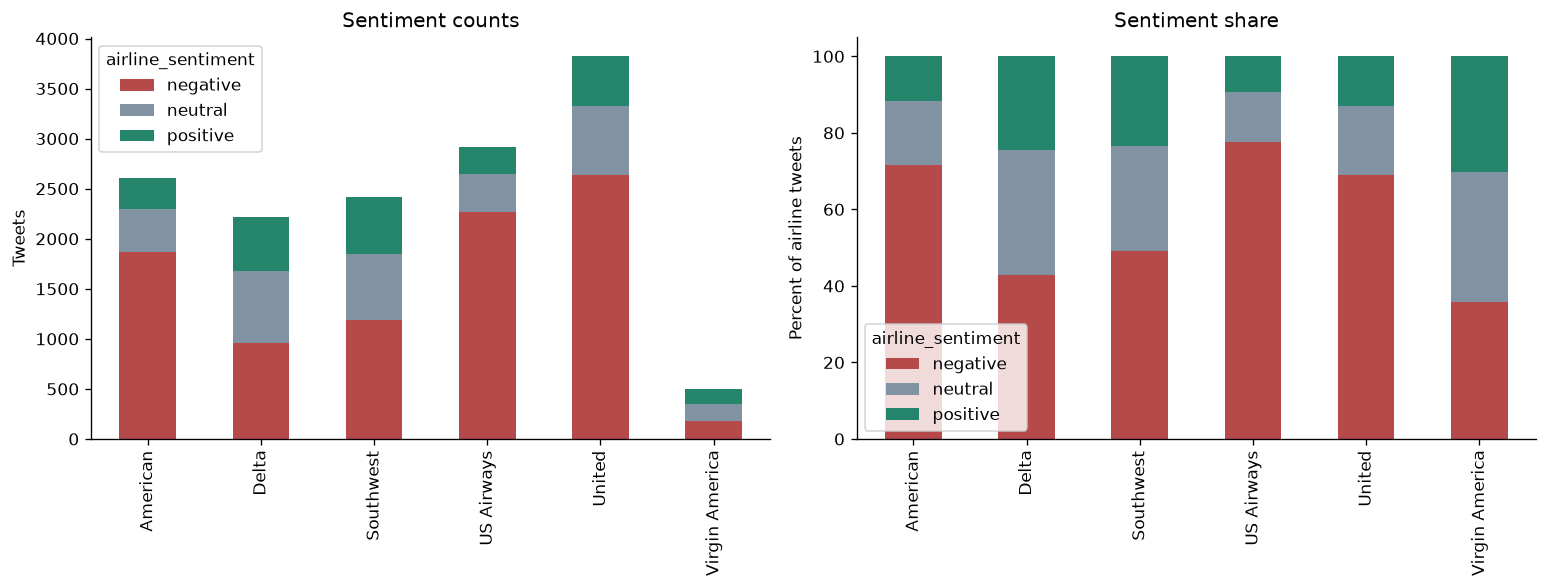

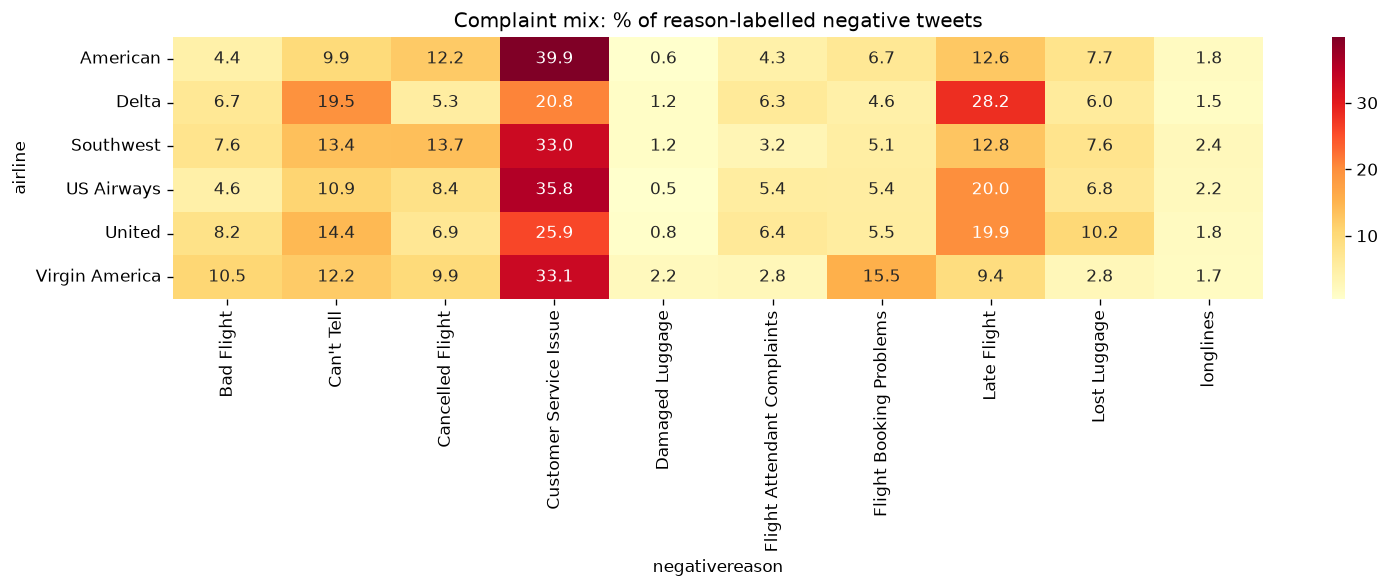

,service_pct,operations_pct
airline,,
American,39.9,33.1
Delta,20.8,40.6
Southwest,33.0,35.2
US Airways,35.8,35.7
United,25.9,37.9
Virgin America,33.1,24.3


,negative_count_rank,negative_share_rank
airline,,
American,3.0,2.0
Delta,5.0,5.0
Southwest,4.0,4.0
US Airways,2.0,1.0
United,1.0,3.0
Virgin America,6.0,6.0


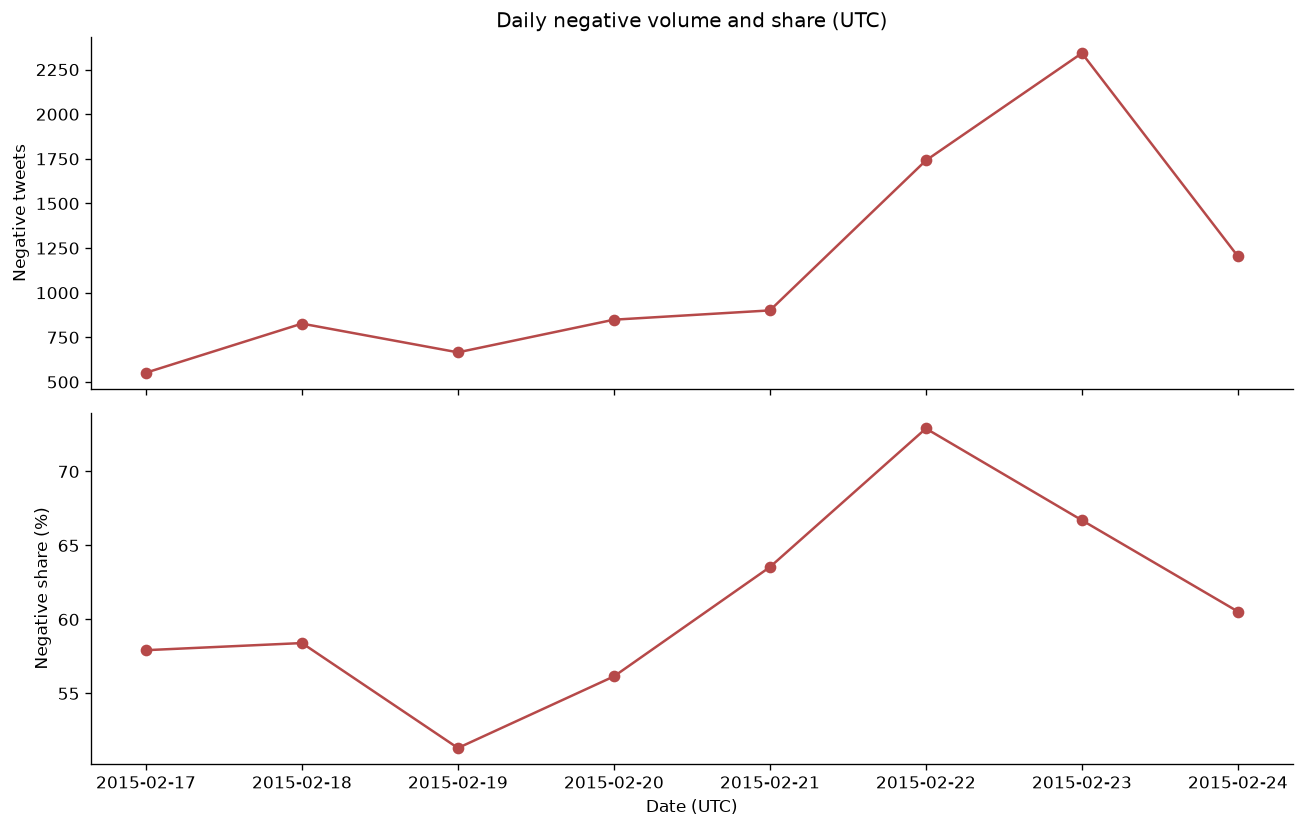

airline_sentiment,negative,neutral,positive,total,negative_pct
date,,,,,
2015-02-17 00:00:00+00:00,552,220,181,953,57.9
2015-02-18 00:00:00+00:00,827,304,285,1416,58.4
2015-02-19 00:00:00+00:00,666,346,286,1298,51.3
2015-02-20 00:00:00+00:00,849,383,280,1512,56.2
2015-02-21 00:00:00+00:00,901,272,245,1418,63.5
2015-02-22 00:00:00+00:00,1741,367,280,2388,72.9
2015-02-23 00:00:00+00:00,2342,711,458,3511,66.7
2015-02-24 00:00:00+00:00,1204,466,319,1989,60.5


,tweet_id,airline,text,retweet_count,priority_score
6578,567772246060433408,Southwest,@SouthwestAir you Cancelled Flightled my flight to BNA. I have flight from BNA 2 MDW tomorrow AM. You stranded me in DEN. I've been on hold all day,0,6
4206,567778009013178368,United,@united So what do you offer now that my flight was Cancelled Flighted and I'm stranded away from home and work?,0,6
11701,567807786748284928,US Airways,"@USAirways stranded @Ernie_Vigil Phoenix w/ broken foot. Both my flights f'd, Sunday for ""sickcrew"". Cancelled Flighted my mechanics flight today.",0,6
11627,567864395264573441,US Airways,@USAirways My daughter is stranded in charlotte because US Airways Cancelled Flightled her flight tonight. Completely dissatisfied with @USAirways,0,6
6425,567866673325285376,Southwest,@SouthwestAir why are you the only airlines to Cancelled Flight all flights into BNA? Been stranded in philly for 2 days. Hoping to get out in the AM,0,6
3464,568421732157161472,United,"@united please explain why I need to pay bag fees twice, equally $1200, because a delayed flight resulted in bags being rechecked overnight?",0,6
3163,568624487031132162,United,@united Cancelled Flightled my flight for some unknown reason and haven't really given me anything to make my overnight layover tolerable,0,6
2809,568887455044259842,United,@United you need to get it together 3 of 4 flights Cancelled Flightled stranded with no car and my baggage is lost! You NEVER get it right.,1,6
5477,568957365464076288,Southwest,@SouthwestAir Cancelled Flightled my flight and I'm stranded in St. Louis. Not sure what to do. No other flight until tomorrow. Am I to sleep in airpt,0,6
7907,568996575617409026,Delta,@JetBlue says the person who hasn't been delayed for hours and now sitting on a runway with a wailing baby ;),0,6


In [6]:
composition=pd.crosstab(df.airline,df.airline_sentiment).reindex(columns=labels)
shares=composition.div(composition.sum(axis=1),axis=0)
display(composition.assign(total=composition.sum(axis=1),negative_share=shares.negative).round(3))
fig,axes=plt.subplots(1,2,figsize=(13,5))
composition.plot.bar(stacked=True,ax=axes[0],color=['#b64949','#8193a3','#25856b']);axes[0].set(title='Sentiment counts',ylabel='Tweets',xlabel='')
(shares*100).plot.bar(stacked=True,ax=axes[1],color=['#b64949','#8193a3','#25856b']);axes[1].set(title='Sentiment share',ylabel='Percent of airline tweets',xlabel='');plt.tight_layout();plt.show()
reasons=pd.crosstab(df.loc[df.airline_sentiment.eq('negative'),'airline'],df.loc[df.airline_sentiment.eq('negative'),'negativereason'])
reason_share=reasons.div(reasons.sum(axis=1),axis=0)*100
fig,ax=plt.subplots(figsize=(13,5));sns.heatmap(reason_share,annot=True,fmt='.1f',cmap='YlOrRd',ax=ax);ax.set_title('Complaint mix: % of reason-labelled negative tweets');plt.tight_layout();plt.show()
service=['Customer Service Issue']; operations=['Late Flight','Cancelled Flight','Lost Luggage','Damaged Luggage']
comparison=pd.DataFrame({'service_pct':reason_share.reindex(columns=service,fill_value=0).sum(axis=1),'operations_pct':reason_share.reindex(columns=operations,fill_value=0).sum(axis=1)})
display(comparison.round(1))
rank=pd.DataFrame({'negative_count_rank':composition.negative.rank(ascending=False,method='min'),'negative_share_rank':shares.negative.rank(ascending=False,method='min')})
display(rank)
daily=pd.crosstab(df.date,df.airline_sentiment).reindex(columns=labels,fill_value=0)
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].plot(daily.index,daily.negative,marker='o');axes[0].set(ylabel='Negative tweets',title='Daily negative volume and share (UTC)')
axes[1].plot(daily.index,100*daily.negative/daily.sum(axis=1),marker='o');axes[1].set(ylabel='Negative share (%)',xlabel='Date (UTC)');plt.tight_layout();plt.show()
display(daily.assign(total=daily.sum(axis=1),negative_pct=100*daily.negative/daily.sum(axis=1)).round(1))
# Triage is a suggested policy, not a validated measure of passenger harm.
df['urgent_cue']=df.text.str.contains(r'(?i)\b(?:stranded|overnight|medication|medicine|wheelchair|disabled|baby|infant|unsafe|emergency)\b',regex=True)
df['disruption_cue']=df.text.str.contains(r'(?i)\b(?:cancelled|canceled|missed|lost|delayed)\b',regex=True)
df['priority_score']=np.where(df.airline_sentiment.eq('negative'),4*df.urgent_cue.astype(int)+2*df.disruption_cue.astype(int)+(df.retweet_count>=2).astype(int),0)
queue=df[df.airline_sentiment.eq('negative')].sort_values(['priority_score','tweet_created'],ascending=[False,True])
display(queue[['tweet_id','airline','text','retweet_count','priority_score']].head(10))
queue.to_csv('dataset/priority_queue.csv',index=False)

**Decision.** Compare the highest service share with the highest operations share below. The operations bucket combines four reasons while service has one, so its size is definition-dependent; “Can't Tell” and “Other” remain in the denominator. A hypothesis about a particular unnamed airline cannot be uniquely tested; the full comparison shows candidates, not proof of operational performance.

The response rule gives four points for urgent safety/accessibility/vulnerability cues, two for disruption, and one for at least two retweets. Human negative labels are used to demonstrate the queue; production should admit any urgent-cue tweet even if the model misses negativity. Review oldest first within a priority tier, verify keyword matches, and never let popularity override safety. Names, coordinates and timezones are not used to infer vulnerability.

Daily charts distinguish absolute spikes from negative-share changes. Edge dates may be partial; collection volume can explain spikes. One short period cannot establish seasonality or causal explanations such as weather without external evidence.

**Count/share example:** United has the most negative tweets (2,633), but its negative share is 68.9%, below US Airways (77.7%) and American (71.6%). Report both count for staffing demand and share for comparison within this sample, always with total n. February 23 has the largest negative count (2,342), while February 22 has the highest negative share (72.9%). Neither establishes why the increase occurred.

## Part E — Limits and the staffing decision
1. Twitter users and people mentioning airlines are self-selected; dissatisfied passengers may be overrepresented. These are not passenger satisfaction rates.
2. Airlines differ in passenger volume, social-media use and query coverage. Tweet counts cannot rank service quality per journey.
3. Multiple tweets can describe the same incident or come from the same author. Observations are dependent, and duplicate-ID removal does not solve event duplication.
4. Labels, reason categories and confidence scores reflect annotator judgments. Mixed sentiment and sarcastic language undermine a single “ground truth.”
5. The short 2015 window, incomplete location information and uncertain collection process limit time and geographic inference. I trust causal explanations of daily spikes and long-term airline rankings least.

With current data, airline identities, operating conditions, customer channels, platform participation, vocabulary and automated-account activity could differ. Therefore airline rankings, complaint mix and model accuracy would likely change; these are hypotheses to remeasure, not claims about today's airlines. The need to preserve negation and compare normalized rates remains.

**Do not replace the manual team.** Use automation to summarize volume, suggest themes and route likely complaints; retain people for urgent cases, sarcasm, mixed sentiment and uncertain labels. Compare accuracy with the majority baseline and inspect class recall before deployment. Evaluate a current, representative, adjudicated holdout and measure missed urgent complaints, not only aggregate accuracy.

## Part F — Three additional decision insights
These go beyond word themes, overall sentiment shares and time spikes: author concentration, amplification coverage and annotation ambiguity. Each has a reproducible number and a bounded recommendation.

In [7]:
authors=df.name.value_counts(); top_n=max(1,int(np.ceil(len(authors)*.01))); author_share=authors.head(top_n).sum()/len(df)
negative_df=df[df.airline_sentiment.eq('negative')]
zero_rt=negative_df.retweet_count.eq(0).mean()
conf=df.groupby('airline_sentiment').airline_sentiment_confidence.agg(['mean','median','count'])
uncertain=df.assign(low=df.airline_sentiment_confidence.lt(.8)).groupby('airline_sentiment').low.mean()
display(conf.round(3));display(uncertain.to_frame('share_confidence_below_0.8').round(3))
insights=[
('A small author segment contributes repeated observations.',f'Top 1% of observed handles ({top_n} of {len(authors)}) contribute {author_share:.1%} of tweets; {authors.gt(1).sum()} handles post more than once.','Tweet totals can overrepresent a smaller set of experiences.','Track unique authors alongside tweet volume and consolidate ongoing conversations before assigning agents.','Direct sample counts are reliable; a handle is not necessarily one passenger and one author can report several incidents.'),
('Retweet-only triage would overlook most ordinary complaints.',f'{zero_rt:.1%} of human-negative tweets have zero recorded retweets.','Low public amplification does not mean low passenger impact.','Use retweets only as a tie-breaker after urgency; reserve queue capacity for zero-retweet cases.','Retweet counts are a snapshot; later amplification and quote tweets are unavailable.'),
('Annotation uncertainty differs across sentiment classes.',f'The largest below-0.8 confidence share is {uncertain.idxmax()} at {uncertain.max():.1%}; the smallest is {uncertain.idxmin()} at {uncertain.min():.1%}.','Evaluation and review workload depend on class-specific ambiguity.','Double-review ambiguous labels and report performance by confidence band before model procurement.','Confidence is annotator agreement, not a calibrated probability of truth; filtering alters sample composition.')]
for i,(obs,evidence,why,action,limits) in enumerate(insights,1):
    display(Markdown(f'### Insight {i}\n**Observation:** {obs}\n\n**Evidence:** {evidence}\n\n**Why it matters:** {why}\n\n**Recommended action:** {action}\n\n**Confidence and limits:** {limits}'))
known=errors.cause_proxy.value_counts().drop('Other / requires manual review',errors='ignore')
findings={'rows':len(df),'accuracy':accuracy,'baseline':baseline,'macro_f1':f1_score(df.airline_sentiment,df.vader_label,average='macro'),'hardest_class':hardest,'largest_error_proxy':str(known.idxmax()),'largest_error_proxy_n':int(known.max()),'other_errors':int(errors.cause_proxy.eq('Other / requires manual review').sum()),'service_airline':comparison.service_pct.idxmax(),'service_pct':comparison.service_pct.max(),'operations_airline':comparison.operations_pct.idxmax(),'operations_pct':comparison.operations_pct.max(),'peak_date':str(daily.negative.idxmax().date()),'peak_negative':int(daily.negative.max()),'author_share':author_share,'zero_retweet_negative_share':zero_rt}
Path('findings.json').write_text(json.dumps(findings,indent=2))
display(Markdown(f"**Measured conclusions:** VADER agrees on {accuracy:.1%} of tweets against a {baseline:.1%} majority baseline; {hardest} has the lowest F1. The largest identifiable error proxy is **{known.idxmax()}** ({known.max()} errors); {findings['other_errors']} remain unclassified. **{findings['service_airline']}** has the highest service share ({findings['service_pct']:.1f}%), while **{findings['operations_airline']}** has the highest defined operations share ({findings['operations_pct']:.1f}%). The largest daily negative volume is {findings['peak_negative']} on {findings['peak_date']} UTC."))
export=df.drop(columns=['tokens']).copy();export['tokens']=df.tokens.map(json.dumps)
export.to_csv('dataset/tweets_cleaned.csv',index=False)
print('Saved cleaned/scored dataset, disagreement audit, priority queue and findings.')

,mean,median,count
airline_sentiment,,,
negative,0.933,1.000,9082
neutral,0.823,0.732,3069
positive,0.871,1.000,2334


,share_confidence_below_0.8
airline_sentiment,
negative,0.195
neutral,0.500
positive,0.359


### Insight 1
**Observation:** A small author segment contributes repeated observations.

**Evidence:** Top 1% of observed handles (78 of 7701) contribute 7.9% of tweets; 2949 handles post more than once.

**Why it matters:** Tweet totals can overrepresent a smaller set of experiences.

**Recommended action:** Track unique authors alongside tweet volume and consolidate ongoing conversations before assigning agents.

**Confidence and limits:** Direct sample counts are reliable; a handle is not necessarily one passenger and one author can report several incidents.

### Insight 2
**Observation:** Retweet-only triage would overlook most ordinary complaints.

**Evidence:** 93.4% of human-negative tweets have zero recorded retweets.

**Why it matters:** Low public amplification does not mean low passenger impact.

**Recommended action:** Use retweets only as a tie-breaker after urgency; reserve queue capacity for zero-retweet cases.

**Confidence and limits:** Retweet counts are a snapshot; later amplification and quote tweets are unavailable.

### Insight 3
**Observation:** Annotation uncertainty differs across sentiment classes.

**Evidence:** The largest below-0.8 confidence share is neutral at 50.0%; the smallest is negative at 19.5%.

**Why it matters:** Evaluation and review workload depend on class-specific ambiguity.

**Recommended action:** Double-review ambiguous labels and report performance by confidence band before model procurement.

**Confidence and limits:** Confidence is annotator agreement, not a calibrated probability of truth; filtering alters sample composition.

**Measured conclusions:** VADER agrees on 54.3% of tweets against a 62.7% majority baseline; neutral has the lowest F1. The largest identifiable error proxy is **Negation cue** (1699 errors); 3463 remain unclassified. **American** has the highest service share (39.9%), while **Delta** has the highest defined operations share (40.6%). The largest daily negative volume is 2342 on 2015-02-23 UTC.

Saved cleaned/scored dataset, disagreement audit, priority queue and findings.


### Additional data-integrity finding — airline labels and altered wording
Inspection revealed strings that look like prior substitutions rather than natural tweet wording. The source also labels many tweets addressed to `@JetBlue` as “Delta.” Preserve the supplied category for reproducibility, but do not silently interpret it as a verified airline identity. This limits the “Delta operations” conclusion materially.

In [8]:
altered=df.text.str.contains(r'Cancelled Flight|Late Flight|Flight Booking Problems',case=False,regex=True)
handle_mismatch=df.airline.eq('Delta') & df.text.str.contains('@JetBlue',case=False,regex=False)
print('Tweets with apparent substituted phrases:',altered.sum(),f'({altered.mean():.1%})')
print('Delta-labelled tweets mentioning @JetBlue:',handle_mismatch.sum(),'of',df.airline.eq('Delta').sum())
display(df.loc[altered,['text']].head(5))
print('Observation: source wording and airline attribution need verification. Evidence: counts above. Why it matters: phrase frequency and competitor advice may reflect upstream edits. Action: request the original export and category mapping before operational use. Confidence/limits: the strings are observable, but the edit history is unknown.')

Tweets with apparent substituted phrases: 1525 (10.5%)
Delta-labelled tweets mentioning @JetBlue: 2218 of 2222


,text
30,"@VirginAmerica hi! I just bked a cool birthday trip with you, but i can't add my elevate no. cause i entered my middle name during Flight Booking Problems 😢"
82,@VirginAmerica you're the best!! Whenever I (begrudgingly) use any other airline I'm delayed and Late Flight :(
83,@VirginAmerica I have no interesting flying with you after this. I will Cancelled Flight my next four flights I planned.#neverflyvirginforbusiness
86,@VirginAmerica Can't bring up my reservation online using Flight Booking Problems code
92,@VirginAmerica I like the TV and interesting video . Just disappointed in Cancelled Flightled flight when other flights went out to jfk on Saturday .


Observation: source wording and airline attribution need verification. Evidence: counts above. Why it matters: phrase frequency and competitor advice may reflect upstream edits. Action: request the original export and category mapping before operational use. Confidence/limits: the strings are observable, but the edit history is unknown.


## Reproduction and submission
All charts are generated from the supplied data, with fixed random seed 42 for the cloud. Topic charts use cleaned text; sentiment uses original text. The notebook saves derived CSVs alongside the original. The HTML embeds the charts and requires no CDN or JavaScript. Serve this folder using `python3 -m http.server 8000` and open the HTML.

The manual requires both GCR and a section GitHub repository. This package is prepared locally; upload destinations and section naming must be confirmed before submission. No remote submission is claimed.